# OmniPath table ingestion

[OmniPath](https://omnipathdb.org/) is a database of molecular interactions. Its
Python client, [omnipath-client](https://omnipath.sysbioverse.org/), builds an
AnnNet graph from an interaction table with `omnipath_client.to_annnet`. AnnNet
itself does not connect to a knowledge base: the client of the knowledge base
returns AnnNet objects. This notebook uses a small local table in the OmniPath
format, so the result is always the same.

To run this notebook, create the environment from
[`omnipath_table_ingestion.yml`](../environments/omnipath_table_ingestion.yml).
See [Reproduce an example](../index.md#reproduce-an-example).

## Build a graph from a local table

The table is a [Polars](https://pola.rs/) data frame. `to_annnet` takes the
column names for the endpoints, the edge IDs, the direction and the weight.
The other listed columns become edge attributes.

In [2]:
import omnipath_client as oc
import polars as pl

interactions = pl.DataFrame(
    {
        'source': ['EGF', 'EGFR', 'EGFR', 'EGFR', 'RAS', 'MEK'],
        'target': ['EGFR', 'RAS', 'RAS', 'GRB2', 'MEK', 'ERK'],
        'interaction_id': [
            'EGF_EGFR',
            'EGFR_RAS_primary',
            'EGFR_RAS_secondary',
            'EGFR_GRB2_complex',
            'RAS_MEK',
            'MEK_ERK',
        ],
        'is_directed': [True, True, True, False, True, True],
        'curation_score': [0.95, 0.88, 0.63, 0.76, 0.82, 0.79],
        'consensus_direction': [1, 1, 1, 0, 1, 1],
        'source_database': [
            'omnipath',
            'omnipath',
            'literature',
            'complexportal',
            'pathwayextra',
            'kinaseextra',
        ],
    }
)

anet = oc.to_annnet(
    interactions,
    source_col='source',
    target_col='target',
    edge_id_col='interaction_id',
    directed_col='is_directed',
    weight_col='curation_score',
    edge_attr_cols=['consensus_direction', 'source_database'],
)

print('shape:', anet.shape)
anet.attrs.table('edges', derived=True).select(
    ['edge_id', 'source', 'target', 'effective_weight', 'source_database']
)

shape: (6, 6)


edge_id,source,target,effective_weight,source_database
str,str,str,f64,str
"""EGF_EGFR""","""EGF""","""EGFR""",0.95,"""omnipath"""
"""EGFR_RAS_primary""","""EGFR""","""RAS""",0.88,"""omnipath"""
"""EGFR_RAS_secondary""","""EGFR""","""RAS""",0.63,"""literature"""
"""EGFR_GRB2_complex""","""EGFR""","""GRB2""",0.76,"""complexportal"""
"""RAS_MEK""","""RAS""","""MEK""",0.82,"""pathwayextra"""
"""MEK_ERK""","""MEK""","""ERK""",0.79,"""kinaseextra"""


## Add analysis context as slices

A slice is a named selection of edges. The `high_confidence` slice keeps the
interactions with a weight of 0.85 or more.

In [3]:
rows = list(anet.attrs.table('edges', derived=True).iter_rows(named=True))
edge_label = {row['edge_id']: f'{row["source"]} -> {row["target"]}' for row in rows}
high_confidence = [row['edge_id'] for row in rows if row['effective_weight'] >= 0.85]
anet.slices.add('high_confidence')
anet.slices.add_edges('high_confidence', high_confidence)

print(
    'high-confidence interactions:',
    [edge_label[eid] for eid in sorted(anet.slices.edges('high_confidence'))],
)

high-confidence interactions: ['EGFR -> RAS', 'EGF -> EGFR']


## Draw the network

The edge labels show the source database of each interaction.

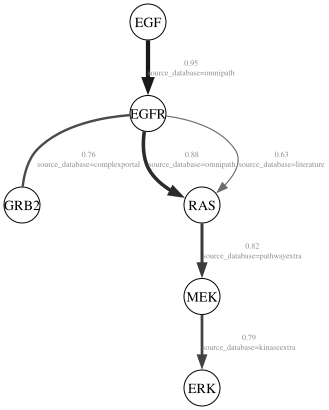

In [4]:
from annnet.utils import plotting

plotting.plot(
    anet,
    backend='graphviz',
    show_edge_labels=True,
    edge_label_keys=['source_database'],
)

The graph from the client keeps the confidence, the source database and every
analysis context in one object. The client is responsible for the origin of the
table. AnnNet is responsible for what the analysis does with the graph.